# Mortgage denial rates in New York State 2025 (HMDA)

**Question.** Among home-purchase mortgage applications in New York in 2025, how do denial rates differ across lenders, loan types and applicant groups, and which differences remain after accounting for applicants' basic financial profile?

**Data.** Public Home Mortgage Disclosure Act (HMDA) loan-level data from the FFIEC HMDA Data Browser (https://ffiec.cfpb.gov/data-browser/): year 2025, state New York, all records. Field definitions follow the 2018-onward data dictionary (https://ffiec.cfpb.gov/documentation/publications/loan-level-datasets/lar-data-fields/).

To reproduce: download the CSV from the Data Browser and place it in `data/`. The raw file is not committed to this repository

This notebook covers:
1. Loading and filtering the data to first-lien, owner-occupied, home-purchase applications
2. Section 1: baseline approval and denial rates
3. Section 2: denial rates by loan type and income band
4. Section 3: lenders with unusually high or low denial rates, after accounting for each lender's mix of applications
5. Section 4: denial rates by applicant race and ethnicity, and how much the gaps shrink when comparing applicants with similar income, debt-to-income ratio, loan-to-value ratio and loan type
6. SQL: three questions answered in SQLite
7. Findings and limitations

## Setup

Find the raw CSV IN `data/`. The notebook expects exactly one CSV file there.

In [2]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA_DIR = Path("./data")
FIG_DIR = Path("./figures")
FIG_DIR.mkdir(exist_ok=True)

csv_files = sorted(DATA_DIR.glob("*.csv"))
assert len(csv_files) == 1, f"Expected one CSV in {DATA_DIR}, found: {csv_files}"
RAW_PATH = csv_files[0]
print(RAW_PATH, f"({RAW_PATH.stat().st_size / 1e6:,.0f} MB)")


data/state_NY.csv (163 MB)


## Load the data

The public file has about 99 columns. To keep memory use low, I load only the columns this analysis needs. First I check that each one exists in the file.

In [3]:
COLUMNS = [
    # identifiers and geography
    "activity_year", "lei", "derived_msa-md", "county_code",
    # filters
    "action_taken", "loan_purpose", "lien_status", "occupancy_type", "total_units",
    "reverse_mortgage", "business_or_commercial_purpose",
    # loan and financial profile
    "loan_type", "loan_amount", "property_value", "loan_to_value_ratio",
    "income", "debt_to_income_ratio", "ffiec_msa_md_median_family_income",
    # applicant groups
    "derived_race", "derived_ethnicity", "derived_sex", "applicant_age",
    # outcome detail
    "denial_reason-1",
]

header = pd.read_csv(RAW_PATH, nrows=0).columns
missing = [col for col in COLUMNS if col not in header]
print(f"{len(header)} columns in file. Missing from my list: {missing or 'none'}")

99 columns in file. Missing from my list: none


In [4]:
raw = pd.read_csv(RAW_PATH, usecols=[col for col in COLUMNS if col in header], low_memory=False)
print(f"{len(raw):} rows, {raw.shape[1]} columns")
raw["activity_year"].value_counts()

430554 rows, 23 columns


activity_year
2025    430554
Name: count, dtype: int64

## Check the codes before filtering

Each filter below relies on a numeric code from the data dictionary. Before filtering, I print the values that actually appear in the file, including missing values.

| Field | Code used | Meaning |
|---|---|---|
| action_taken | 1, 3 | 1 = Loan originated, 3 = Application denied |
| loan_purpose | 1 | Home purchase |
| lien_status | 1 | Secured by a first lien |
| occupancy_type | 1 | Principal residence |
| total_units | "1" to "4" | Stored as text; larger buildings are reported in ranges such as "5-24" |

In [5]:
for col in ["action_taken", "loan_purpose", "lien_status", "occupancy_type", "total_units"]:
    print(f"---{col}---")
    print(raw[col].value_counts(dropna=False).sort_index().to_string(), "\n")

---action_taken---
action_taken
1    232239
2     10961
3     76984
4     47782
5     21791
6     36518
7       434
8      3845 

---loan_purpose---
loan_purpose
1     202124
2      61191
4      50715
5       1113
31     49958
32     65453 

---lien_status---
lien_status
1    314666
2    115888 

---occupancy_type---
occupancy_type
1    370413
2     10248
3     49893 

---total_units---
total_units
1          378484
100-149       182
2           36517
25-49         595
3            7386
4            3324
5-24         3331
50-99         459
>149          276 



## Apply the filters

I keep applications that ended in a clear decision: originated (approved and closed) or denied. This drops withdrawn and incomplete files, purchases loans and preapproval requests. It also drops "approved but not accepted" (code 2), which keeps the comparison to approved and closed versus denied; that choice is noted as limitation.

The row count is printed after each step.

In [6]:
filter_log = [{"step": "Raw file", "rows": len(raw)}]

def keep(data, mask, label):
    out = data[mask]
    filter_log.append({"step": label, "rows": len(out)})
    print(f"{label:<48}{len(out):>12,} rows (dropped {len(data) - len(out):,})")
    return out

df = raw
df = keep(df, df["action_taken"].isin([1, 3]), "Originated or denied (action_taken 1, 3)")
df = keep(df, df["loan_purpose"] == 1, "Home purchase (loan_purpose 1)")
df = keep(df, df["lien_status"] == 1, "First lien (lien_status 1)")
df = keep(df, df["occupancy_type"] == 1, "Principal residence (occupancy_type 1)")
df = keep(df, df["total_units"].astype(str).isin(["1", "2", "3", "4"]), "1 to 4 units (total_units)")

df = df.copy()
filter_log = pd.DataFrame(filter_log)
filter_log

Originated or denied (action_taken 1, 3)             309,223 rows (dropped 121,331)
Home purchase (loan_purpose 1)                       138,106 rows (dropped 171,117)
First lien (lien_status 1)                           134,464 rows (dropped 3,642)
Principal residence (occupancy_type 1)               113,150 rows (dropped 21,314)
1 to 4 units (total_units)                           113,145 rows (dropped 5)


,step,rows
0,Raw file,430554
1,"Originated or denied (action_taken 1, 3)",309223
2,Home purchase (loan_purpose 1),138106
3,First lien (lien_status 1),134464
4,Principal residence (occupancy_type 1),113150
5,1 to 4 units (total_units),113145


## Create the outcome and clean numeric fields

`approved` = 1 if the loan was originated, `denied` = 1 if the application was denied. Income is reported in thousands of dollars. Some numeric fields contain text such as "NA" or "Exempt", so I convert them and treat those values as missing.


In [7]:
df["approved"] = (df["action_taken"] == 1).astype(int)
df["denied"] = (df["action_taken"] == 3).astype(int)

for col in ["income", "loan_amount", "property_value", "loan_to_value_ratio", "ffiec_msa_md_median_family_income"]:
    if col in df:
        df[col] = pd.to_numeric(df[col], errors="coerce")

# Income of zero or less is not usable for income bands
df.loc[df["income"] <= 0, "income"] = np.nan

print(df[["loan_amount", "property_value", "loan_to_value_ratio"]].isna().mean().rename("share missing").to_string())

loan_amount            0.000000
property_value         0.034858
loan_to_value_ratio    0.059181


## Section 1: Baseline approval and denial rates

In [8]:
baseline = pd.Series({
    "Applications": len(df),
    "Originated": df["approved"].sum(),
    "Denied": df["denied"].sum(),
    "Approval rate": df["approved"].mean(),
    "Denial rate": df["denied"].mean(),
    "Distinct lenders (LEI)": df["lei"].nunique(),
})
baseline.to_frame("Value")

,Value
Applications,113145.000000
Originated,99788.000000
Denied,13357.000000
Approval rate,0.881948
Denial rate,0.118052
Distinct lenders (LEI),454.000000


Most common first-listed denial reason, amoung denied aplications (codes from the data dictionary). Lenders may report up to four reasons; HMDA does not rank them, so this counts only the first one listed.

In [9]:
DENIAL_REASON = {
    1: "Debt-to-income ratio",
    2: "Employment history",
    3: "Credit history",
    4: "Collateral",
    5: "Insufficient cash (downpayment, closing costs)",
    6: "Unverifiable information",
    7: "Credit application incomplete",
    8: "Mortgage insurance denied",
    9: "Other",
    10: "Not applicable",
}

denied = df[df["denied"] == 1]
(denied["denial_reason-1"].map(DENIAL_REASON).value_counts(normalize=True)
 .rename("share of denials").to_frame())

,share of denials
denial_reason-1,
Debt-to-income ratio,0.330510
Collateral,0.233211
Credit history,0.155678
Other,0.098672
Credit application incomplete,0.057998
Unverifiable information,0.052808
"Insufficient cash (downpayment, closing costs)",0.050824
Employment history,0.019536
Mortgage insurance denied,0.000763


**Findings, Section 1.**

After filtering, the sample contains 113,145 first-lien, owner-occupied, 1 to 4 unit home-purchase applications from 454 lenders. Of these, 11.8% were denied. The three most common first-listed denial reasons were debt-to-income ratio (33.1% of denials), collateral (23.3%) and credit history (15.6%), which together account for 71.9% of denials.

## Section 2: Denial rates by loan type and income band

A helper function computes the number of applications, the denial rate, and an approximate 95% confidence interval for each group. Groups with fewer than 30 applications are flagged, because their rates are too noisy to interpret.

In [10]:
MIN_N = 30

def denial_table(data, by):
    t = (data.groupby(by, observed=True)["denied"]
         .agg(applications="size", denials="sum", denial_rate = "mean"))
    se = np.sqrt(t["denial_rate"] * (1 - t["denial_rate"]) / t["applications"])
    t["ci_low"] = (t["denial_rate"] - 1.96 * se).clip(lower=0)
    t["ci_high"] = (t["denial_rate"] + 1.96 * se).clip(upper=1)
    t["small_n"] = t["applications"] < MIN_N
    return t

### 2a. By loan type

In [11]:
LOAN_TYPE = {1: "Conventional", 2: "FHA", 3: "VA", 4: "USDA"}
df["loan_type_name"] = df["loan_type"].map(LOAN_TYPE)

by_loan_type = denial_table(df, "loan_type_name").sort_values("applications", ascending=False)
by_loan_type

,applications,denials,denial_rate,ci_low,ci_high,small_n
loan_type_name,,,,,,
Conventional,96096,10834,0.112741,0.110742,0.114741,False
FHA,12537,1991,0.158810,0.152412,0.165208,False
VA,4208,463,0.110029,0.100574,0.119483,False
USDA,304,69,0.226974,0.179886,0.274061,False


### 2b. By income band

Incomes in New York City and upstates are very different, so a fixed dollar band would mostly sort applicants by region. Instead I compare each applicant's income to the median family income of their metro are (`ffiec_msa_md_median_family_income`), using bands similar to the low anda moderate income definitions in fair lending work.

In [12]:
df["income_pct_of_area_median"] = (
    100 * df["income"] * 1000 / df["ffiec_msa_md_median_family_income"]
)

INCOME_BINS = [0, 50, 80, 120, 200, np.inf]
INCOME_LABELS = ["Under 50%", "50% to 80 %", "80% to 120%", "120% to 200%", "Over 200%"]
df["income_band"] = pd.cut(df["income_pct_of_area_median"], bins=INCOME_BINS,
                           labels=INCOME_LABELS, right=False)

print(f"Share with no income band (income or area median missing): "
      f"{df['income_band'].isna().mean():.1%}")
by_income = denial_table(df, "income_band")
by_income

Share with no income band (income or area median missing): 2.4%


,applications,denials,denial_rate,ci_low,ci_high,small_n
income_band,,,,,,
Under 50%,7512,2445,0.325479,0.314883,0.336075,False
50% to 80 %,21949,3196,0.145610,0.140944,0.150277,False
80% to 120%,29011,2969,0.102340,0.098853,0.105828,False
120% to 200%,29936,2443,0.081607,0.078506,0.084709,False
Over 200%,22006,1697,0.077115,0.073591,0.080640,False


### 2c. Loan type and income band together

This table shows whether the income pattern holds within each loan type. Cells with fewer than 30 applications are left blank.

In [13]:
main_types = ["Conventional", "FHA", "VA"]
cross = denial_table(df[df["loan_type_name"].isin(main_types)], ["loan_type_name","income_band"])

rate_grid = cross["denial_rate"].where(~cross["small_n"]).unstack("loan_type_name")[main_types]
count_grid = cross["applications"].unstack("loan_type_name")[main_types]

print("Denial rate")
display(rate_grid.style.format("{:.1%}", na_rep=""))
print("Applications")
display(count_grid)

Denial rate


loan_type_name,Conventional,FHA,VA
income_band,,,
Under 50%,32.8%,29.6%,40.8%
50% to 80 %,14.2%,15.9%,14.3%
80% to 120%,9.8%,13.0%,8.3%
120% to 200%,7.5%,13.9%,7.7%
Over 200%,7.4%,15.7%,10.2%


Applications


loan_type_name,Conventional,FHA,VA
income_band,,,
Under 50%,6201,1120,157
50% to 80 %,17428,3452,935
80% to 120%,23208,4265,1415
120% to 200%,25671,2952,1301
Over 200%,20964,658,384


### Chart 1: Denial rate by income band and loan type

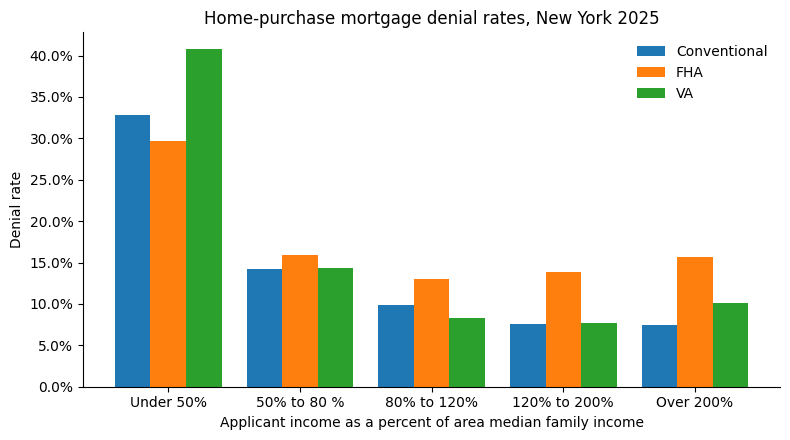

In [14]:
fig, ax = plt.subplots(figsize=(8, 4.5))
x = np.arange(len(INCOME_LABELS))
width = 0.27
for i, lt in enumerate(main_types):
    ax.bar(x + (i-1)*width, rate_grid[lt].reindex(INCOME_LABELS), width, label=lt)

ax.set_xticks(x, INCOME_LABELS)
ax.set_xlabel("Applicant income as a percent of area median family income")
ax.set_ylabel("Denial rate")
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
ax.set_title("Home-purchase mortgage denial rates, New York 2025")
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig(FIG_DIR / "denial_rate_by_income_and_loan_type.png", dpi=150)
plt.show()

**Findings, Section 2.**

Denial rates fall steeply as income rises: 32.5% of applicants earning under 50% of the area median were denied, against 7.7% of those earning over 200%. Most of the drop happens between the two lowest bands.

The pattern differs by loan type. Conventional rates fall across every band. FHA rates stop falling after the 80% to 120% band and rise to 15.7% for the highest incomes, about twice the conventional rate (7.4%). Among the three main types, FHA has the highest denial rate overall (15.9%, against 11.3% for conventional and 11.0% for VA) and in every band except the lowest.

In the lowest band VA is highest at 40.8%, but this rests on only 157 applications (95% interval roughly 33% to 48%), so its gap with conventional (32.8%) is uncertain.

These are raw rates. They do not adjust for credit score, debt, or down payment, and the 2.4% of applications with no income band are excluded.

## Financial profile bands

Sections 3 and 4 compare applications with a similar financial profile. Public HMDA data has no credit scores, so the profile is built from three reported fields plus loan type:

- **Income band**: applicant income as a percent of area median family income (defined in Section 2b)
- **Debt-to-income (DTI) band**: HMDA reports DTI in ranges below 36% and above 50%, and as exact whole numbers from 36 to 49. I group the exact values at 43%, a common underwriting threshold.
- **Loan-to-value (LTV) band**: loan amount as a percent of property value, grouped at 80%, 90% and 95%

Missing or exempt values get their own "Missing" band instead of being dropped, so every application stays in the analysis.

First, check the DTI values that actually appear in the file.

In [17]:
df["debt_to_income_ratio"].value_counts(dropna=False).sort_index()

debt_to_income_ratio
20%-<30%    16657
30%-<36%    17402
36           3235
37           3456
38           3616
39           3753
40           4010
41           4084
42           4390
43           4032
44           4393
45           3947
46           3918
47           4076
48           4457
49           6765
50%-60%      8121
<20%         4805
>60%         3036
Exempt       3147
NaN          1845
Name: count, dtype: int64

In [18]:
DTI_FIXED = {
    "<20%": "Under 20%",
    "20%-<30%": "20 to 30%",
    "30%-<36%": "30 to 36%",
    "50%-60%": "50 to 60%",
    ">60%": "Over 60%",
}
DTI_ORDER = ["Under 20%", "20 to 30%", "30 to 36%", "36 to 43%", "43 to 50%",
             "50 to 60%", "Over 60%", "Missing"]

def dti_band(value):
    if pd.isna(value):
        return "Missing"
    value = str(value).strip()
    if value in DTI_FIXED:
        return DTI_FIXED[value]
    try:
        number = float(value)          # exact values 36 to 49
    except ValueError:
        return "Missing"               # "Exempt", "NA"
    return "36 to 43%" if number < 43 else "43 to 50%"

df["dti_band"] = pd.Categorical(df["debt_to_income_ratio"].map(dti_band),
                                categories=DTI_ORDER, ordered=True)

LTV_ORDER = ["80% or less", "80 to 90%", "90 to 95%", "Over 95%", "Missing"]
df["ltv_band"] = pd.cut(df["loan_to_value_ratio"], bins=[0, 80, 90, 95, np.inf],
                        labels=LTV_ORDER[:-1])
df["ltv_band"] = df["ltv_band"].cat.add_categories("Missing").fillna("Missing")

df["income_cell"] = df["income_band"].cat.add_categories("Missing").fillna("Missing")

for col in ["income_cell", "dti_band", "ltv_band"]:
    print(f"--- {col} ---")
    print(df[col].value_counts(normalize=True).sort_index().map("{:.1%}".format).to_string(), "\n")

--- income_cell ---
income_cell
Under 50%        6.6%
50% to 80 %     19.4%
80% to 120%     25.6%
120% to 200%    26.5%
Over 200%       19.4%
Missing          2.4% 

--- dti_band ---
dti_band
Under 20%     4.2%
20 to 30%    14.7%
30 to 36%    15.4%
36 to 43%    23.5%
43 to 50%    27.9%
50 to 60%     7.2%
Over 60%      2.7%
Missing       4.4% 

--- ltv_band ---
ltv_band
80% or less    50.1%
80 to 90%      14.0%
90 to 95%      13.2%
Over 95%       16.7%
Missing         5.9% 



## Section 3: Lenders with unusually high or low denial rates

A lender's raw denial rate partly reflects who applies to it. A lender that mostly makes FHA loans to applicants with high DTI will deny more often than one that serves high-income applicants with large down payments, even if both apply the same standards.

So for each lender I compare its **observed** denials with the denials **expected** if each of its applications had the statewide denial rate for applications in the same profile cell (loan type, income band, DTI band, LTV band). This is called indirect standardization.

- **O/E ratio** = observed denials / expected denials. Above 1 means more denials than its applicant mix predicts.
- **z-score** = (observed - expected) / standard deviation. It measures how surprising the difference is given the lender's size. I flag lenders with |z| > 3.

I only rank lenders with at least 100 applications, because rates for small lenders are too noisy.

In [19]:
PROFILE = ["loan_type_name", "income_cell", "dti_band", "ltv_band"]
MIN_APPS = 100
Z_FLAG = 3

df["expected_p"] = df.groupby(PROFILE, observed=True)["denied"].transform("mean")
df["expected_var"] = df["expected_p"] * (1 - df["expected_p"])

lenders = df.groupby("lei").agg(
    applications=("denied", "size"),
    observed=("denied", "sum"),
    expected=("expected_p", "sum"),
    variance=("expected_var", "sum"),
)
lenders["denial_rate"] = lenders["observed"] / lenders["applications"]
lenders["expected_rate"] = lenders["expected"] / lenders["applications"]
lenders["o_e_ratio"] = lenders["observed"] / lenders["expected"]
lenders["z"] = (lenders["observed"] - lenders["expected"]) / np.sqrt(lenders["variance"])

ranked = lenders[lenders["applications"] >= MIN_APPS].sort_values("z", ascending=False)
print(f"{len(ranked)} of {len(lenders)} lenders have at least {MIN_APPS} applications, "
      f"covering {ranked['applications'].sum() / len(df):.1%} of all applications.")
print(f"Flagged high (z > {Z_FLAG}): {(ranked['z'] > Z_FLAG).sum()}   "
      f"Flagged low (z < -{Z_FLAG}): {(ranked['z'] < -Z_FLAG).sum()}")

151 of 454 lenders have at least 100 applications, covering 94.7% of all applications.
Flagged high (z > 3): 32   Flagged low (z < -3): 40


Lenders with the most denials above expectation:

In [20]:
show_cols = ["applications", "denial_rate", "expected_rate", "o_e_ratio", "z"]
fmt = {"applications": "{:,}", "denial_rate": "{:.1%}", "expected_rate": "{:.1%}",
       "o_e_ratio": "{:.2f}", "z": "{:.1f}"}
ranked[show_cols].head(10).style.format(fmt)

,applications,denial_rate,expected_rate,o_e_ratio,z
lei,,,,,
549300Q3ROEQU3D1IW91,454,75.6%,35.1%,2.15,27.0
549300JYXTZDSPJEPI44,"1,296",32.7%,13.9%,2.36,24.3
549300FGXN1K3HLB1R50,"3,962",21.5%,11.2%,1.91,23.3
SS1TRMSN6BRNMOREEV51,361,44.6%,15.6%,2.85,19.6
549300S347HTLHLOC775,248,85.5%,49.1%,1.74,18.1
5493001WHVQBGRSWEU75,566,31.4%,11.9%,2.65,17.5
C5654JQHZUHN0772B561,346,42.8%,16.9%,2.53,16.3
549300FFVDRROF85IC57,266,60.5%,32.0%,1.89,15.3
B4TYDEB6GKMZO031MB27,"1,853",24.1%,14.6%,1.65,15.1


Lenders with the fewest denials relative to expectation:

In [21]:
ranked[show_cols].tail(10).sort_values("z").style.format(fmt)

,applications,denial_rate,expected_rate,o_e_ratio,z
lei,,,,,
549300T3F9S1MKFKHC53,"3,463",2.0%,8.7%,0.23,-14.7
254900XN7UWEWK13RO81,"4,679",2.9%,8.5%,0.34,-14.6
549300RJW4T6MPVUPK44,"2,060",1.7%,8.0%,0.21,-11.2
549300YKTME1U7Z0UN20,700,4.4%,15.5%,0.29,-10.1
549300BRR67NLTQSBT29,595,2.5%,13.4%,0.19,-9.4
549300VZVN841I2ILS84,"4,154",4.4%,8.0%,0.54,-9.3
549300S5NLOTO329NX77,276,2.5%,17.5%,0.15,-8.3
254900641GGR26VXNC67,611,2.9%,12.4%,0.24,-8.1
549300CLRXFVF83ZL806,"1,639",4.5%,9.7%,0.46,-7.6


Lenders are identified by their Legal Entity Identifier (LEI). Names can be looked up at https://search.gleif.org/#/search/.

Note: the expected rates include each lender's own applications, so for the largest lenders the comparison is slightly conservative.

**Findings, Section 3.** 

I ranked the 151 lenders with at least 100 applications, which together account for 94.7% of the sample. After accounting for loan type, income, DTI and LTV, lenders still differ much more than chance would predict: 32 have significantly more denials than expected and 40 significantly fewer (|z| > 3). Among the most extreme, the highest denial rates are 1.7 to 2.9 times their expected rate, including one lender with 3,962 applications that denied 21.5% against an expected 11.2%. Several large lenders deny 2% to 4.5% of applications against expected rates of 8% to 9%.

These differences may reflect applicant credit profiles not in public HMDA data, differences in products, or how lenders record applications that are withdrawn before a decision. Lenders at either extreme are candidates for closer review with fuller data, not evidence of unfair treatment on their own.

## Section 4: Denial rates by applicant group

### Defining applicant groups

HMDA reports race and ethnicity separately (`derived_race`, `derived_ethnicity`). I combine them in the standard way:

- **Hispanic or Latino**: applicants reported as Hispanic or Latino, of any race
- **White, Black, Asian**: applicants of that race who are not reported as Hispanic or Latino
- **Other or joint**: other races, two or more minority races, and joint applications where co-applicants differ
- **Not available**: race not reported

Check the raw values first.

In [22]:
pd.crosstab(df["derived_race"], df["derived_ethnicity"], margins=True)

derived_ethnicity,Ethnicity Not Available,Free Form Text Only,Hispanic or Latino,Joint,Not Hispanic or Latino,All
derived_race,,,,,,
2 or more minority races,15,0,62,15,253,345
American Indian or Alaska Native,27,0,149,8,214,398
Asian,346,8,168,109,14264,14895
Black or African American,262,2,646,148,6532,7590
Free Form Text Only,1,2,4,2,7,16
Joint,66,0,158,453,2295,2972
Native Hawaiian or Other Pacific Islander,8,0,58,5,79,150
Race Not Available,10790,1,1956,222,2010,14979
White,1953,11,6814,2064,60958,71800


In [24]:
eth = df["derived_ethnicity"]
race = df["derived_race"]

df["group"] = np.select(
    [eth =="Hispanic or Latino",
     race == "White",
     race == "Black or African American",
     race == "Asian",
     race == "Race Not Available"],
    ["Hispanic or Latino", "White", "Black", "Asian", "Not available"],
        default="Other or joint",
)

GROUP_ORDER = ["White", "Black", "Hispanic or Latino", "Asian", "Other or joint", "Not available"]
REFERENCE = "White"
df["group"].value_counts().reindex(GROUP_ORDER)

group
White                 64986
Black                  6944
Hispanic or Latino    10015
Asian                 14727
Other or joint         3450
Not available         13023
Name: count, dtype: int64

### 4a. Raw denial rates by group

The gap is measured in percentage points (pp) relative to White applicants, the largest group.

In [25]:
by_group = (df.groupby("group")["denied"]
              .agg(applications="size", denial_rate="mean")
              .reindex(GROUP_ORDER))
ref_rate = by_group.loc[REFERENCE, "denial_rate"]
by_group["gap_pp"] = 100 * (by_group["denial_rate"] - ref_rate)
by_group["ratio_to_white"] = by_group["denial_rate"] / ref_rate

by_group.style.format({"applications": "{:,}", "denial_rate": "{:.1%}",
                       "gap_pp": "{:+.1f}", "ratio_to_white": "{:.2f}"})

,applications,denial_rate,gap_pp,ratio_to_white
group,,,,
White,"64,986",10.1%,+0.0,1.00
Black,"6,944",19.2%,+9.2,1.91
Hispanic or Latino,"10,015",16.7%,+6.7,1.67
Asian,"14,727",12.0%,+1.9,1.19
Other or joint,"3,450",10.8%,+0.8,1.08
Not available,"13,023",12.9%,+2.8,1.28


### 4b. How much of the gap remains among similar applicants?

Some of the raw gap map reflect differences in income, debt and down payment. To compare like with like, I ask: **What would each group's denial rate be if its applicants were denied at the same rate as White applicants with the same profile?**

For each group:
1. Put each applicant in a profile cell (for example: FHA, 50% to 80% of area median income, DTI 43% TO 50%, LTV over 95%).
2. Look up the denial rate of White applicants in that same cell. This is the applicant's **expected** denial probabiliy.
3. **Adjusted gap** = the group's observed denial rate minus its average expected rate.

I add the profile fields one at a time to show how the gap shrinks. Cells with fewer than 20 White applicants are skipped because their rates are noisy; the `coverage` table shows what share of each group could be matched.

In [26]:
CONTROL_SETS = {
    "No controls": [],
    "Income": ["income_cell"],
    "Income + DTI": ["income_cell", "dti_band"],
    "Income + DTI + LTV + loan type": ["income_cell", "dti_band", "ltv_band", "loan_type_name"],
}
MIN_REF = 20

def adjusted_gap(data, controls):
    if not controls:
        rates = data.groupby("group")["denied"].mean()
        return pd.DataFrame({"gap_pp": 100 * (rates - rates[REFERENCE]), "coverage": 1.0})

    cell = data.groupby(controls, observed=True).ngroup()
    is_ref = data["group"] == REFERENCE
    ref_cells = data.loc[is_ref, "denied"].groupby(cell[is_ref]).agg(["mean", "size"])
    ref_cells = ref_cells.loc[ref_cells["size"] >= MIN_REF, "mean"]

    expected = cell.map(ref_cells)
    matched = expected.notna()
    out = (data[matched].assign(expected=expected[matched])
             .groupby("group")
             .agg(observed=("denied", "mean"), expected=("expected", "mean"),
                  n_matched=("denied", "size")))
    out["gap_pp"] = 100 * (out["observed"] - out["expected"])
    out["coverage"] = out["n_matched"] / data.groupby("group").size()
    return out[["gap_pp", "coverage"]]

results = {name: adjusted_gap(df, controls) for name, controls in CONTROL_SETS.items()}
gaps = pd.DataFrame({name: r["gap_pp"] for name, r in results.items()}).reindex(GROUP_ORDER)
coverage = pd.DataFrame({name: r["coverage"] for name, r in results.items()}).reindex(GROUP_ORDER)

print("Gap in denial rate vs. White applicants (percentage points)")
display(gaps.style.format("{:+.1f}"))
print("Share of each group matched to a profile cell")
display(coverage.style.format("{:.0%}"))

Gap in denial rate vs. White applicants (percentage points)


,No controls,Income,Income + DTI,Income + DTI + LTV + loan type
group,,,,
White,+0.0,+0.0,+0.0,+0.0
Black,+9.2,+8.5,+5.4,+6.3
Hispanic or Latino,+6.7,+6.1,+4.3,+4.9
Asian,+1.9,+2.2,+0.8,+2.0
Other or joint,+0.8,+2.1,+1.6,+1.4
Not available,+2.8,+3.2,+1.8,+2.1


Share of each group matched to a profile cell


,No controls,Income,Income + DTI,Income + DTI + LTV + loan type
group,,,,
White,100%,100%,100%,96%
Black,100%,100%,100%,93%
Hispanic or Latino,100%,100%,100%,96%
Asian,100%,100%,100%,98%
Other or joint,100%,100%,100%,96%
Not available,100%,100%,100%,96%


Share of the raw gap that remains after all controls (shown only where the raw gap is at least 1 percentage point):

In [27]:
full = list(CONTROL_SETS)[-1]
remaining = (gaps[full] / gaps["No controls"]).where(gaps["No controls"] >= 1)
remaining.drop(REFERENCE).rename("share of raw gap remaining").to_frame().style.format("{:.0%}", na_rep="")

,share of raw gap remaining
group,
Black,69%
Hispanic or Latino,74%
Asian,104%
Other or joint,
Not available,73%


### Chart 2: Denial gap vs. White applicants, before and after accounting for financial profile

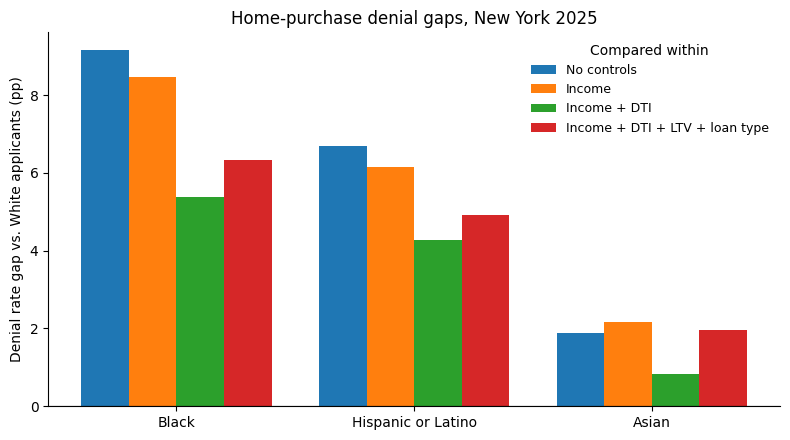

In [28]:
plot_groups = ["Black", "Hispanic or Latino", "Asian"]
plot_data = gaps.loc[plot_groups]

fig, ax = plt.subplots(figsize=(8, 4.5))
x = np.arange(len(plot_groups))
n_sets = len(CONTROL_SETS)
width = 0.8 / n_sets
for i, name in enumerate(CONTROL_SETS):
    ax.bar(x + (i - (n_sets - 1) / 2) * width, plot_data[name], width, label=name)

ax.axhline(0, color="black", linewidth=0.8)
ax.set_xticks(x, plot_groups)
ax.set_ylabel("Denial rate gap vs. White applicants (pp)")
ax.set_title("Home-purchase denial gaps, New York 2025")
ax.legend(title="Compared within", frameon=False, fontsize=9)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig(FIG_DIR / "denial_gap_by_group_and_controls.png", dpi=150)
plt.show()

**Findings, Section 4.** Black and Hispanic applicants were denied at 19.2% and 16.7%, compared with 10.1% for White applicants, gaps of 9.2 and 6.7 percentage points. Comparing applicants within the same income band barely changes these gaps. Adding debt-to-income ratio reduces them the most, to 5.4 and 4.3 points, consistent with DTI being the most common denial reason. With loan-to-value ratio and loan type also held constant, the gaps are 6.3 points for Black applicants and 4.9 points for Hispanic applicants, so roughly two thirds or more of each raw gap remains. The gap for Asian applicants is about 2 points and is largely unaffected by the controls.

The gap rises slightly when LTV and loan type are added. This comparison drops the 4% to 7% of applicants in profile cells with fewer than 20 White applicants, and it matches applicants more closely on loan product, so it should be read as "the gap does not shrink further" rather than as a precise increase.

**Interpretation.** Public HMDA data does not include credit scores, full credit history, or cash reserves, which lenders use in underwriting. A gap that remains after these controls is a signal worth investigating with fuller data, not proof of discrimination.

## SQL: Loading the cleaned data into SQLite

I load the analysis sample into a SQLite database and answer three questions in SQL. The queries use common table expressions (CTEs), window functions, a cross join and UNION ALL. The database file is saved in `data/`, which is not committed.

In [29]:
import sqlite3

DB_PATH = DATA_DIR / "hmda_ny_2025.db"
SQL_COLS = ["lei", "loan_type_name", "income_cell", "dti_band", "ltv_band", "group",
            "income", "loan_amount", "approved", "denied",
            "denial_reason-1", "denial_reason-2", "denial_reason-3", "denial_reason-4"]

table = df[[c for c in SQL_COLS if c in df]].copy()
for col in table.select_dtypes("category"):
    table[col] = table[col].astype(str)

con = sqlite3.connect(DB_PATH)
table.to_sql("applications", con, if_exists="replace", index=False)
print(pd.read_sql_query("SELECT COUNT(*) AS rows FROM applications", con))

     rows
0  113145


**Q1. Within each loan type, which lenders have the highest denial rates?** A CTE computes each lender's denial rate by loan type (lenders with at least 100 applications of that type), and `RANK()` ranks lenders within each loan type.

In [30]:
q1 = """
WITH lender_stats AS (
    SELECT lei,
           loan_type_name,
           COUNT(*)    AS applications,
           AVG(denied) AS denial_rate
    FROM applications
    GROUP BY lei, loan_type_name
    HAVING COUNT(*) >= 100
)
SELECT loan_type_name,
       lei,
       applications,
       ROUND(100 * denial_rate, 1) AS denial_rate_pct,
       RANK() OVER (PARTITION BY loan_type_name ORDER BY denial_rate DESC) AS rank_in_loan_type
FROM lender_stats
ORDER BY loan_type_name, rank_in_loan_type
"""
r1 = pd.read_sql_query(q1, con)
r1[r1["rank_in_loan_type"] <= 3]

,loan_type_name,lei,applications,denial_rate_pct,rank_in_loan_type
0,Conventional,549300S347HTLHLOC775,248,85.5,1
1,Conventional,549300Q3ROEQU3D1IW91,454,75.6,2
2,Conventional,549300XQVJ1XBNFA5536,1143,70.8,3
145,FHA,5493001WHVQBGRSWEU75,116,35.3,1
146,FHA,549300JYXTZDSPJEPI44,416,34.1,2
147,FHA,549300FGXN1K3HLB1R50,834,27.7,3
179,VA,C5654JQHZUHN0772B561,226,39.4,1
180,VA,549300FGXN1K3HLB1R50,153,22.9,2
181,VA,5493003GQDUH26DNNH17,407,14.3,3


**Q2. How does each applicant group's denial rate compare with White applicants?** This reproduces Section 4a in SQL as a check on the pandas results.

In [31]:
q2 = """
WITH group_rates AS (
    SELECT "group", COUNT(*) AS applications, AVG(denied) AS denial_rate
    FROM applications
    GROUP BY "group"
),
reference AS (
    SELECT denial_rate AS white_rate FROM group_rates WHERE "group" = 'White'
)
SELECT g."group",
       g.applications,
       ROUND(100 * g.denial_rate, 1)                  AS denial_rate_pct,
       ROUND(100 * (g.denial_rate - r.white_rate), 1) AS gap_pp,
       ROUND(g.denial_rate / r.white_rate, 2)         AS ratio_to_white
FROM group_rates AS g
CROSS JOIN reference AS r
ORDER BY g.denial_rate DESC
"""
pd.read_sql_query(q2, con)

,group,applications,denial_rate_pct,gap_pp,ratio_to_white
0,Black,6944,19.2,9.2,1.91
1,Hispanic or Latino,10015,16.7,6.7,1.67
2,Not available,13023,12.9,2.8,1.28
3,Asian,14727,12.0,1.9,1.19
4,Other or joint,3450,10.8,0.8,1.08
5,White,64986,10.1,0.0,1.00


**Q3. Do denial reasons differ across applicant groups?** Lenders can report up to four reasons. `UNION ALL` stacks the four reason columns into one, so every reason cited is counted. Shares can add up to more than 100% because a denial can have several reasons.

In [32]:
q3 = """
WITH reasons AS (
    SELECT "group", "denial_reason-1" AS reason FROM applications WHERE denied = 1
    UNION ALL
    SELECT "group", "denial_reason-2" FROM applications WHERE denied = 1
    UNION ALL
    SELECT "group", "denial_reason-3" FROM applications WHERE denied = 1
    UNION ALL
    SELECT "group", "denial_reason-4" FROM applications WHERE denied = 1
),
denials AS (
    SELECT "group", COUNT(*) AS n_denied FROM applications WHERE denied = 1 GROUP BY "group"
)
SELECT r."group",
       CASE CAST(r.reason AS INTEGER)
            WHEN 1 THEN 'Debt-to-income ratio'
            WHEN 2 THEN 'Employment history'
            WHEN 3 THEN 'Credit history'
            WHEN 4 THEN 'Collateral'
            WHEN 5 THEN 'Insufficient cash'
            WHEN 6 THEN 'Unverifiable information'
            WHEN 7 THEN 'Credit application incomplete'
            WHEN 8 THEN 'Mortgage insurance denied'
            WHEN 9 THEN 'Other'
       END AS reason,
       ROUND(100.0 * COUNT(*) / d.n_denied, 1) AS pct_of_denials_citing
FROM reasons AS r
JOIN denials AS d ON d."group" = r."group"
WHERE r.reason IS NOT NULL AND CAST(r.reason AS INTEGER) BETWEEN 1 AND 9
  AND r."group" IN ('White', 'Black', 'Hispanic or Latino', 'Asian')
GROUP BY r."group", reason
ORDER BY r."group", pct_of_denials_citing DESC
"""
pd.read_sql_query(q3, con)

,group,reason,pct_of_denials_citing
0,Asian,Debt-to-income ratio,32.3
1,Asian,Collateral,28.4
2,Asian,Other,10.8
3,Asian,Unverifiable information,8.3
4,Asian,Credit history,6.4
5,Asian,Insufficient cash,5.1
6,Asian,Credit application incomplete,4.7
7,Asian,Employment history,1.6
8,Asian,Mortgage insurance denied,0.1
9,Black,Debt-to-income ratio,33.1


In [33]:
con.close()

## Findings and limitations

### Summary of findings

Q2 reproduces the Section 4a denial rates and gaps exactly, which confirms the pandas results. 

Q1 shows that several of the lenders flagged in Section 3 also have the highest denial rates within their loan type; one lender ranks in the top three for both FHA and VA loans, and the highest conventional denial rates (71% to 86%) belong to lenders whose applicant mix is already high risk. 

In Q3, debt-to-income ratio and collateral are the two most cited reasons for every group. Credit history is cited less often for Black (16.3%) and Hispanic (12.0%) denials than for White denials (18.9%), while unverifiable information is cited about twice as often for Hispanic and Asian denials. Because these are shares among denied applications, a similar mix of reasons means groups are denied for similar stated reasons, not that the reasons explain the difference in denial rates.

### Limitations

- **No credit scores.** Public HMDA data does not include credit scores, full credit history, or cash reserves, which lenders use in underwriting. Gaps that remain after controls are signals worth investigating with fuller data, not proof of discrimination.
- **Decisions only.** The sample keeps originated and denied applications. Applications that were withdrawn, incomplete, or approved but not accepted are excluded, so lenders that discourage weak applications before a decision can appear to have low denial rates.
- **Coarse financial profile.** DTI is reported in ranges outside 36% to 49%, and income and DTI are self-reported at application. Applicants in the same profile cell can still differ in ways the data does not show.
- **Race and ethnicity reporting.** Some applicants do not report race or ethnicity, and joint applications combine co-applicants. These are kept as separate groups instead of being assigned.
- **One year, one state.** Results describe New York home-purchase applications in 2025 and may not hold in other years or markets